# Phase 10 — Context-Cube Spectral Dynamics

**Goal:** extend Phase 8 from Möbius interaction coefficients to an exact spectral description of the \(2^n\) context-subset cube.

For \(n=4\) evidence cards, Phase 8 defines

\[
F:\{0,1\}^4\rightarrow\mathbb R,
\]

where \(F(S)\) is correctness / success probability for context subset \(S\).

The natural Fourier basis on this domain is not the ordinary FFT over a line. It is the **Walsh–Hadamard / Boolean Fourier basis**.

This phase measures:

- Walsh spectrum;
- spectral energy by interaction order;
- robustness to one-card perturbations;
- graph-Laplacian smoothness / stability;
- diffusion time scales on the context cube;
- optional Schrödinger-style evolution on the cube as a mathematical analogue.

## Why this follows Phase 8 naturally

Phase 8 already computes the Möbius expansion

\[
F(S)=\sum_{T\subseteq S}m(T).
\]

Möbius coefficients are excellent for causal interaction interpretation.

Walsh coefficients instead expand \(F\) in an **orthogonal basis**:

\[
\hat F(A)
=
2^{-n}
\sum_{x\in\{0,1\}^n}
F(x)(-1)^{A\cdot x}.
\]

Orthogonality gives Parseval energy and clean notions of spectral concentration, filtering and graph dynamics.

So:

- **Möbius:** "which subsets cooperate?"
- **Walsh:** "at which Boolean frequencies / orders does the response surface live?"

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_EVIDENCE = 4
N_STATES = 1 << N_EVIDENCE

RESULT_CANDIDATES = [
    "phase8_qwen06_raw_results.csv",
    "phase8_frontier_raw_results.csv",
]

RESULT_PATH = None
for p in RESULT_CANDIDATES:
    if os.path.exists(p):
        RESULT_PATH = p
        break

if RESULT_PATH is None:
    raise FileNotFoundError(
        "Run Phase 8 first or place one of the expected raw result CSV files "
        "in the working directory."
    )

results = pd.read_csv(RESULT_PATH)
print("using:", RESULT_PATH)
print("rows:", len(results))

using: phase8_qwen06_raw_results.csv
rows: 192


In [2]:
def mask_order(mask):
    return int(mask).bit_count()

valid = results[
    results["error"].isna()
    & results["correct"].notna()
].copy()

F_df = (
    valid
    .groupby(["provider","task_id","family","mask"])
    .agg(
        F=("correct","mean"),
        n=("correct","size"),
    )
    .reset_index()
)

display(F_df.head())

,provider,task_id,family,mask,F,n
0,local,0,direct,0,1.0,1
1,local,0,direct,1,1.0,1
2,local,0,direct,2,1.0,1
3,local,0,direct,3,1.0,1
4,local,0,direct,4,1.0,1


# A. Walsh–Hadamard transform

We use the convention

\[
\hat F(A)=2^{-n}\sum_x F(x)(-1)^{A\cdot x}.
\]

With this normalization,

\[
2^{-n}\sum_x F(x)^2
=
\sum_A \hat F(A)^2.
\]

That gives a clean energy decomposition by order \(|A|\).

In [3]:
def fwht(a):
    x = np.asarray(a, dtype=float).copy()
    n = len(x)
    h = 1
    while h < n:
        for i in range(0, n, h * 2):
            u = x[i:i+h].copy()
            v = x[i+h:i+2*h].copy()
            x[i:i+h] = u + v
            x[i+h:i+2*h] = u - v
        h *= 2
    return x

def walsh_coefficients(f):
    f = np.asarray(f, dtype=float)
    return fwht(f) / len(f)

def walsh_reconstruct(coeff):
    coeff = np.asarray(coeff, dtype=float)
    return fwht(coeff)

walsh_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    coeff = walsh_coefficients(f)
    recon = walsh_reconstruct(coeff)
    err = float(np.max(np.abs(f - recon)))
    family = d["family"].iloc[0]

    for mask, c in enumerate(coeff):
        walsh_rows.append({
            "provider": provider,
            "task_id": task_id,
            "family": family,
            "frequency_mask": mask,
            "order": mask_order(mask),
            "walsh": float(c),
            "energy": float(c*c),
            "reconstruction_error": err,
        })

walsh_df = pd.DataFrame(walsh_rows)
print("max reconstruction error:", walsh_df["reconstruction_error"].max())
walsh_df.to_csv("phase10_walsh_coefficients.csv", index=False)

max reconstruction error: 0.0


,provider,order,mean_energy,std_energy,n_tasks
0,local,0,0.25,0.452267,12
1,local,1,0.00,0.000000,12
2,local,2,0.00,0.000000,12
3,local,3,0.00,0.000000,12
4,local,4,0.00,0.000000,12


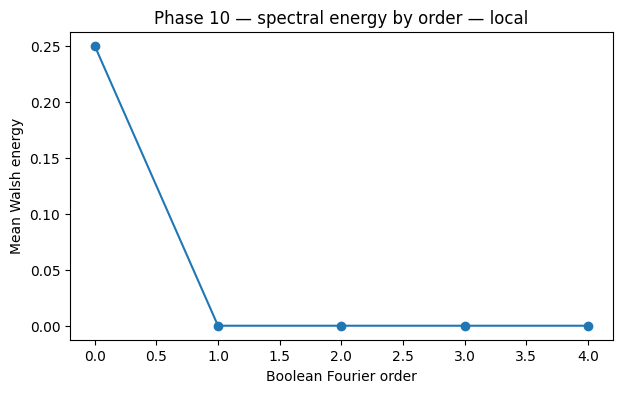

In [4]:
energy_order = (
    walsh_df
    .groupby(["provider","task_id","family","order"])
    .agg(
        energy=("energy","sum"),
        abs_mass=("walsh", lambda x: np.abs(x).sum()),
    )
    .reset_index()
)

energy_summary = (
    energy_order
    .groupby(["provider","order"])
    .agg(
        mean_energy=("energy","mean"),
        std_energy=("energy","std"),
        n_tasks=("task_id","nunique"),
    )
    .reset_index()
)

display(energy_summary)

for provider in sorted(energy_summary["provider"].unique()):
    d = energy_summary[energy_summary["provider"] == provider]
    plt.figure(figsize=(7,4))
    plt.plot(d["order"], d["mean_energy"], marker="o")
    plt.xlabel("Boolean Fourier order")
    plt.ylabel("Mean Walsh energy")
    plt.title(f"Phase 10 — spectral energy by order — {provider}")
    plt.show()

energy_summary.to_csv("phase10_order_energy.csv", index=False)

# B. Stability to context perturbations

A one-card perturbation is a bit flip:

\[
x\rightarrow x\oplus e_i.
\]

Define the discrete derivative

\[
D_iF(x)=F(x\oplus e_i)-F(x).
\]

Then useful robustness metrics are:

\[
S_{\text{mean}}
=
\mathbb E_{x,i}|D_iF(x)|
\]

and

\[
S_{\max}
=
\max_{x,i}|D_iF(x)|.
\]

Smaller values mean the output surface is more stable to adding/removing a single evidence card.

In [5]:
robust_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    family = d["family"].iloc[0]

    diffs = []
    for x in range(N_STATES):
        for bit in range(N_EVIDENCE):
            y = x ^ (1 << bit)
            diffs.append(abs(f[y] - f[x]))

    robust_rows.append({
        "provider": provider,
        "task_id": task_id,
        "family": family,
        "mean_one_bit_sensitivity": float(np.mean(diffs)),
        "max_one_bit_sensitivity": float(np.max(diffs)),
        "rms_one_bit_sensitivity": float(np.sqrt(np.mean(np.square(diffs)))),
    })

robust_df = pd.DataFrame(robust_rows)
display(robust_df)

robust_summary = (
    robust_df
    .groupby(["provider","family"])
    .agg(
        mean_sensitivity=("mean_one_bit_sensitivity","mean"),
        max_sensitivity=("max_one_bit_sensitivity","mean"),
        n_tasks=("task_id","nunique"),
    )
    .reset_index()
)

display(robust_summary)
robust_df.to_csv("phase10_context_stability.csv", index=False)

,provider,task_id,family,mean_one_bit_sensitivity,max_one_bit_sensitivity,rms_one_bit_sensitivity
0,local,0,direct,0.0,0.0,0.0
1,local,1,redundant,0.0,0.0,0.0
2,local,2,pair_chain,0.0,0.0,0.0
3,local,3,triple_chain,0.0,0.0,0.0
4,local,4,dual_path,0.0,0.0,0.0
5,local,5,direct,0.0,0.0,0.0
6,local,6,redundant,0.0,0.0,0.0
7,local,7,pair_chain,0.0,0.0,0.0
8,local,8,triple_chain,0.0,0.0,0.0
9,local,9,dual_path,0.0,0.0,0.0


,provider,family,mean_sensitivity,max_sensitivity,n_tasks
0,local,direct,0.0,0.0,3
1,local,dual_path,0.0,0.0,2
2,local,pair_chain,0.0,0.0,2
3,local,redundant,0.0,0.0,3
4,local,triple_chain,0.0,0.0,2


# C. Hypercube graph Laplacian

The 16 context subsets form the vertices of a 4-dimensional hypercube.

Two vertices are adjacent if they differ by one evidence card.

Let

\[
L=D-A
\]

be the graph Laplacian.

The Walsh characters are exactly the eigenmodes of this graph.

This gives a precise bridge:

\[
\text{context subsets}
\leftrightarrow
\text{spatial graph}
\]

\[
\text{Walsh transform}
\leftrightarrow
\text{graph Fourier transform}.
\]

In [6]:
def hypercube_adjacency(n_bits):
    N = 1 << n_bits
    A = np.zeros((N, N), dtype=float)
    for x in range(N):
        for bit in range(n_bits):
            y = x ^ (1 << bit)
            A[x, y] = 1.0
    return A

A = hypercube_adjacency(N_EVIDENCE)
D = np.diag(A.sum(axis=1))
L = D - A

eigvals, eigvecs = np.linalg.eigh(L)

print("Laplacian eigenvalues:")
print(np.round(eigvals, 8))

Laplacian eigenvalues:
[0. 2. 2. 2. 2. 4. 4. 4. 4. 4. 4. 6. 6. 6. 6. 8.]


## Laplacian smoothness

A standard graph-stability measure is

\[
\mathcal E(F)=F^\top L F
=
\frac12\sum_{x\sim y}(F(x)-F(y))^2.
\]

Low energy means the response changes smoothly under one-card context perturbations.

High energy means strong context sensitivity.

In [7]:
lap_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    family = d["family"].iloc[0]

    energy = float(f.T @ L @ f)
    norm = float(f.T @ f)

    lap_rows.append({
        "provider": provider,
        "task_id": task_id,
        "family": family,
        "laplacian_energy": energy,
        "normalized_laplacian_energy": energy / max(norm, 1e-12),
    })

lap_df = pd.DataFrame(lap_rows)
display(lap_df)
lap_df.to_csv("phase10_laplacian_stability.csv", index=False)

,provider,task_id,family,laplacian_energy,normalized_laplacian_energy
0,local,0,direct,0.0,0.0
1,local,1,redundant,0.0,0.0
2,local,2,pair_chain,0.0,0.0
3,local,3,triple_chain,0.0,0.0
4,local,4,dual_path,0.0,0.0
5,local,5,direct,0.0,0.0
6,local,6,redundant,0.0,0.0
7,local,7,pair_chain,0.0,0.0
8,local,8,triple_chain,0.0,0.0
9,local,9,dual_path,0.0,0.0


# D. Diffusion and time constants on the context cube

A mathematically clean analogue of a stable dissipative dynamics is the graph heat equation:

\[
\frac{\partial \psi}{\partial t}
=
-\kappa L\psi.
\]

Solution:

\[
\psi(t)=e^{-\kappa Lt}\psi(0).
\]

For a Laplacian eigenmode with eigenvalue \(\lambda_k\),

\[
a_k(t)=a_k(0)e^{-\kappa\lambda_k t}.
\]

Therefore its time constant is

\[
\tau_k=\frac{1}{\kappa\lambda_k},
\qquad \lambda_k>0.
\]

On the \(n\)-cube, higher-order Walsh modes have larger Laplacian eigenvalues, hence decay faster under diffusion.

This gives a rigorous meaning to "fast" and "slow" context modes.

In [8]:
KAPPA = 1.0

unique_eigs = sorted(set(np.round(eigvals, 10)))

tau_rows = []
for lam in unique_eigs:
    tau = np.inf if abs(lam) < 1e-12 else 1.0 / (KAPPA * lam)
    tau_rows.append({
        "laplacian_eigenvalue": lam,
        "tau": tau,
    })

tau_df = pd.DataFrame(tau_rows)
display(tau_df)
tau_df.to_csv("phase10_diffusion_time_constants.csv", index=False)

,laplacian_eigenvalue,tau
0,0.0,inf
1,2.0,0.500000
2,4.0,0.250000
3,6.0,0.166667
4,8.0,0.125000


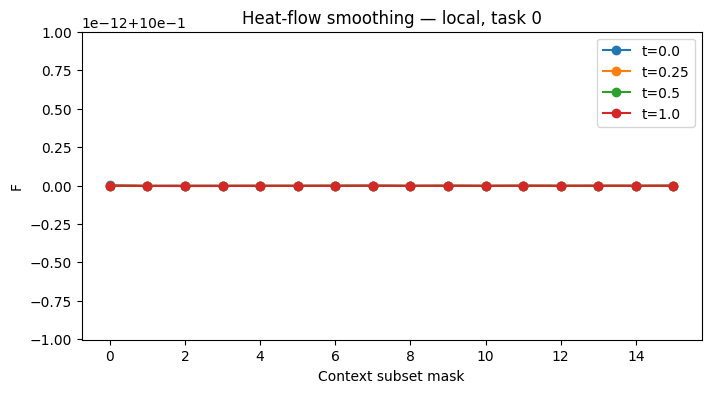

In [9]:
def heat_evolve(f, t, kappa=1.0):
    vals, vecs = np.linalg.eigh(L)
    coeff = vecs.T @ np.asarray(f, dtype=float)
    evolved = coeff * np.exp(-kappa * vals * t)
    return vecs @ evolved

example_group = next(iter(F_df.groupby(["provider","task_id"])), None)

if example_group is not None:
    (provider, task_id), d = example_group
    d = d.sort_values("mask")
    if len(d) == N_STATES:
        f0 = d["F"].to_numpy(dtype=float)

        plt.figure(figsize=(8,4))
        for t in [0.0, 0.25, 0.5, 1.0]:
            ft = heat_evolve(f0, t=t, kappa=KAPPA)
            plt.plot(range(N_STATES), ft, marker="o", label=f"t={t}")

        plt.xlabel("Context subset mask")
        plt.ylabel("F")
        plt.title(f"Heat-flow smoothing — {provider}, task {task_id}")
        plt.legend()
        plt.show()

# E. Schrödinger-style dynamics on the same graph

For comparison, replace dissipative heat flow with

\[
i\frac{\partial\psi}{\partial t}
=
L\psi.
\]

Then

\[
\psi(t)=e^{-iLt}\psi(0).
\]

Unlike diffusion, this evolution preserves the \(L_2\) norm:

\[
\|\psi(t)\|_2=\|\psi(0)\|_2.
\]

So:

- **heat equation:** useful analogue for forgetting, smoothing, stable relaxation;
- **Schrödinger equation:** useful analogue for phase-preserving propagation / interference;
- neither implies that the neural network is physically quantum.

For AI, the value is the mathematical inductive bias: spatial coupling, modes, phase, conservation versus dissipation.

,t,norm,norm_error,mean_probability_mass
0,0.00,4.0,-3.108624e-15,1.0
1,0.25,4.0,-3.108624e-15,1.0
2,0.50,4.0,-3.108624e-15,1.0
3,0.75,4.0,-2.664535e-15,1.0
4,1.00,4.0,-3.108624e-15,1.0
5,1.25,4.0,-2.664535e-15,1.0
6,1.50,4.0,-2.664535e-15,1.0
7,1.75,4.0,-2.664535e-15,1.0
8,2.00,4.0,-3.108624e-15,1.0
9,2.25,4.0,-2.664535e-15,1.0


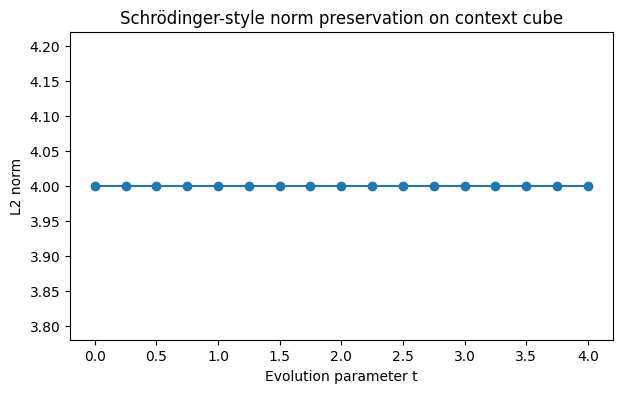

In [10]:
def schrodinger_evolve(psi0, t):
    vals, vecs = np.linalg.eigh(L)
    coeff = vecs.T @ np.asarray(psi0, dtype=complex)
    evolved = coeff * np.exp(-1j * vals * t)
    return vecs @ evolved

if example_group is not None:
    (provider, task_id), d = example_group
    d = d.sort_values("mask")
    if len(d) == N_STATES:
        psi0 = d["F"].to_numpy(dtype=float).astype(complex)

        rows = []
        norm0 = np.linalg.norm(psi0)

        for t in np.linspace(0, 4, 17):
            psi = schrodinger_evolve(psi0, t)
            rows.append({
                "t": float(t),
                "norm": float(np.linalg.norm(psi)),
                "norm_error": float(np.linalg.norm(psi) - norm0),
                "mean_probability_mass": float(np.mean(np.abs(psi)**2)),
            })

        sch_df = pd.DataFrame(rows)
        display(sch_df)

        plt.figure(figsize=(7,4))
        plt.plot(sch_df["t"], sch_df["norm"], marker="o")
        plt.xlabel("Evolution parameter t")
        plt.ylabel("L2 norm")
        plt.title("Schrödinger-style norm preservation on context cube")
        plt.show()

# F. How Phase 9 and Phase 10 fit together

### Phase 9
The "space" is mainly **token position**, while network depth acts as a time-like coordinate.

We measure perturbation propagation directly inside a Transformer.

### Phase 10
The "space" is the **graph of context subsets**.

We know the geometry exactly: a Boolean hypercube.

That makes graph Fourier, diffusion, time constants and Schrödinger-style propagation mathematically exact on the benchmark domain.

## Future bridge

A future model could have a state

\[
\psi(x,\ell)
\]

where \(x\) is token/context position and \(\ell\) is depth, with a learned operator

\[
\mathcal H_\theta
=
\mathcal H_{\text{local}}
+
\mathcal H_{\text{attention}}
+
\mathcal H_{\text{memory}}.
\]

Then the central experimental question becomes:

> do measured causal responses from Phase 7–10 support a compact dynamical law?

That is a much stronger question than merely asking whether Fourier or Schrödinger-inspired layers can be inserted into a Transformer.